# Задание 3. Свои оптимизаторы на FashionMNIST

Реализации — в `optimizers.py` (Momentum, RMSProp, Adam, AdamW), тесты — в `test_optimizers.py`
(в том числе сверка с `torch.optim` до 1e-7 на 30 шагах), описание идей — в `README.md`.

Модель — `BaseNetwork` с ReLU и стандартной инициализацией PyTorch. Для каждого оптимизатора 5 эпох,
batch = 128, в качестве точки отсчёта — обычный SGD из torch. Логируем loss и норму градиента на каждом шаге,
точность на тесте по эпохам и распределение весов по слоям в конце обучения.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

import optimizers as my
from common import BaseNetwork, load_fashion_mnist, train

data = load_fashion_mnist()

OPTIMIZERS = {
    "SGD (torch)": lambda p: torch.optim.SGD(p, lr=0.02),
    "Momentum": lambda p: my.Momentum(p, lr=0.01, momentum=0.9),
    "RMSProp": lambda p: my.RMSProp(p, lr=1e-3),
    "Adam": lambda p: my.Adam(p, lr=1e-3),
    "AdamW": lambda p: my.AdamW(p, lr=1e-3, weight_decay=0.05),
}

torch.manual_seed(0)
init_weights = [m.weight.detach().clone() for m in BaseNetwork(nn.ReLU()).layers if isinstance(m, nn.Linear)]

results, weights = {}, {}
for name, make_opt in OPTIMIZERS.items():
    torch.manual_seed(0)  # одинаковая инициализация и порядок батчей для всех
    model = BaseNetwork(nn.ReLU())
    results[name] = train(model, make_opt(model.parameters()), data, epochs=5)
    weights[name] = [m.weight.detach().clone() for m in model.layers if isinstance(m, nn.Linear)]

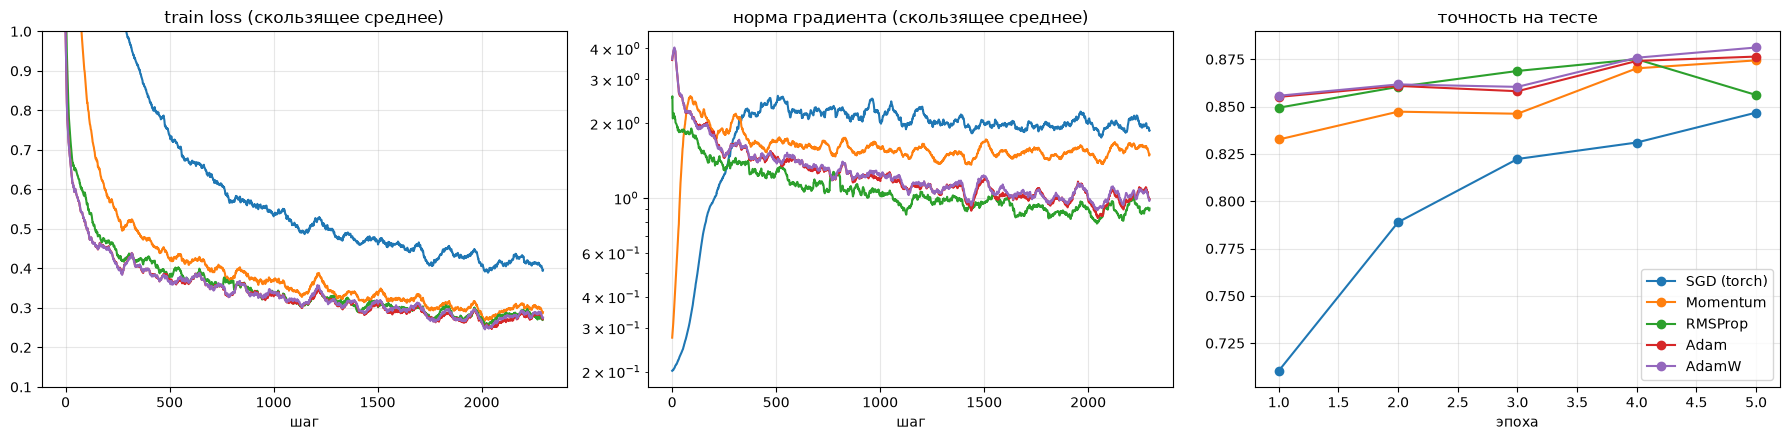

,SGD (torch),Momentum,RMSProp,Adam,AdamW
эпоха,,,,,
1,0.7104,0.8326,0.8494,0.8551,0.8557
2,0.7889,0.8473,0.8604,0.8609,0.8617
3,0.8223,0.8462,0.8688,0.8581,0.8604
4,0.8310,0.8702,0.8750,0.8741,0.8758
5,0.8468,0.8744,0.8561,0.8764,0.8812


In [2]:
def smooth(values, k=50):
    return np.convolve(np.asarray(values), np.ones(k) / k, mode="valid")


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, h in results.items():
    axes[0].plot(smooth(h["loss"]), label=name)
    axes[1].plot(smooth(h["grad_norm"]), label=name)
    axes[2].plot(range(1, len(h["test_acc"]) + 1), h["test_acc"], "o-", label=name)
axes[0].set(title="train loss (скользящее среднее)", xlabel="шаг", ylim=(0.1, 1.0))
axes[1].set(title="норма градиента (скользящее среднее)", xlabel="шаг", yscale="log")
axes[2].set(title="точность на тесте", xlabel="эпоха")
for ax in axes:
    ax.grid(alpha=0.3)
axes[2].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({name: h["test_acc"] for name, h in results.items()}, index=range(1, 6)).rename_axis("эпоха").round(4)

## Распределение весов по слоям после обучения

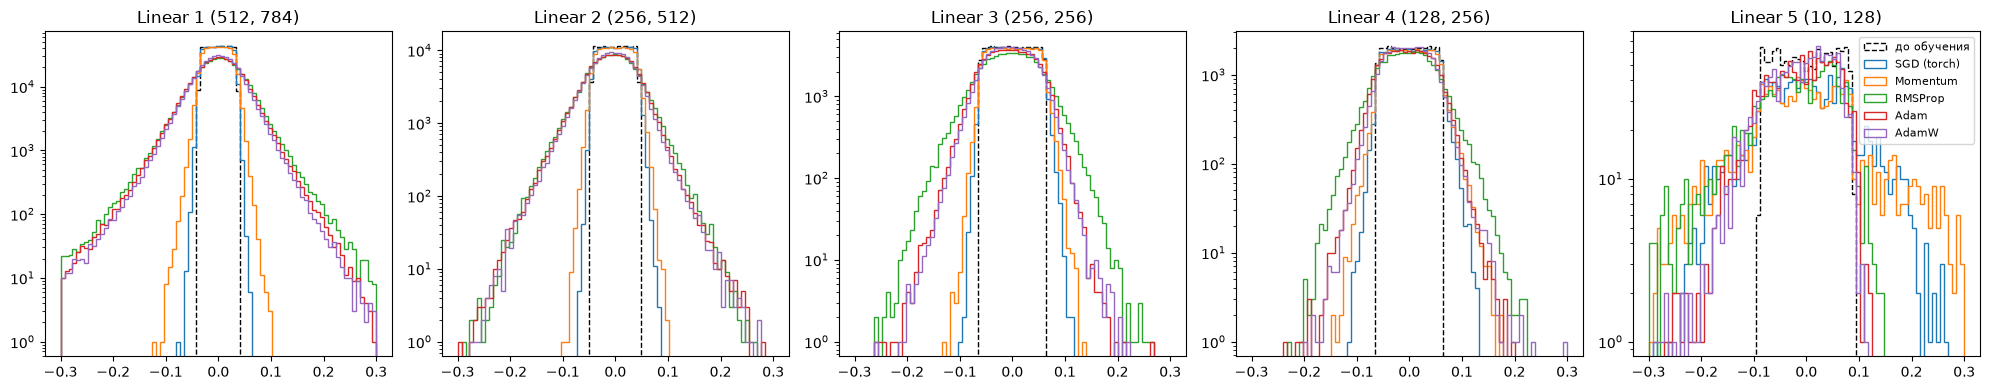

,до обучения,SGD (torch),Momentum,RMSProp,Adam,AdamW
std весов,,,,,,
Linear 1,0.0206,0.0211,0.0227,0.0506,0.0478,0.0448
Linear 2,0.0255,0.0266,0.0279,0.0484,0.0467,0.0446
Linear 3,0.0360,0.0375,0.0387,0.0562,0.0468,0.0443
Linear 4,0.0361,0.0391,0.0414,0.0521,0.0446,0.0421
Linear 5,0.0519,0.0956,0.1232,0.1058,0.0744,0.0727


In [3]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, ax in enumerate(axes):
    bins = np.linspace(-0.3, 0.3, 80)
    ax.hist(init_weights[i].flatten().numpy(), bins=bins, histtype="step", color="k", ls="--", label="до обучения")
    for name, w in weights.items():
        ax.hist(w[i].flatten().numpy(), bins=bins, histtype="step", label=name)
    ax.set_title(f"Linear {i + 1} {tuple(init_weights[i].shape)}")
    ax.set_yscale("log")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

pd.DataFrame(
    {name: [w.std().item() for w in ws] for name, ws in {"до обучения": init_weights, **weights}.items()},
    index=[f"Linear {i + 1}" for i in range(5)],
).round(4).rename_axis("std весов")

## Выводы

- Все четыре реализации учат сеть: за 5 эпох 0.856–0.881 точности против 0.847 у обычного SGD.
  Корректность отдельно проверена в `test_optimizers.py`: после 30 шагов веса совпадают с `torch.optim` до машинной точности.
- **Momentum** заметно быстрее обычного SGD: скорость копит согласованное направление градиентов.
  При этом веса меняются мало (std почти как при инициализации), как и у SGD: шаг пропорционален самому градиенту.
- **RMSProp, Adam, AdamW** уже на первой эпохе дают ≈0.85. Шаг у них нормирован на $\sqrt{v}$, поэтому
  все параметры, даже с маленьким градиентом, двигаются примерно на `lr` за шаг. Отсюда заметно более широкие
  распределения весов в первых слоях (std ≈0.045–0.05 против 0.021 при инициализации) с тяжёлыми хвостами.
- У **RMSProp** нет момента, поэтому кривая самая шумная: точность скачет (0.875 → 0.856 на 5-й эпохе).
- **AdamW** дал лучшую точность (0.881). Распределение весов у него чуть уже, чем у Adam (std меньше во всех слоях):
  weight decay стягивает веса к нулю.
- Норма градиента: у SGD она растёт с 0.2 и держится около 2, потому что сеть медленно выходит из начального плато.
  У адаптивных методов она падает примерно с 4 до 1 по мере выхода на «дно».